<a href="https://colab.research.google.com/github/nazaninharirian18363-cmyk/fashion-mnist-mlp/blob/main/notebooks/fashion_mnist_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Training an MLP on Fashion-MNIST

This project trains a Multi-Layer Perceptron (MLP) with PyTorch to classify
10 categories of clothing images (28×28 grayscale) from the Fashion-MNIST dataset.

Steps:
1. Data loading and preparation
2. Exploratory data analysis (EDA)
3. MLP model definition
4. Training with early stopping and learning-rate scheduling
5. Evaluation on the test set
6. Ablation study comparing architectures


In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Output folders (relative to the notebook's working directory)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


Device: cuda


## 1. Data Loading and Preparation

Fashion-MNIST has 60,000 training and 10,000 test images. We hold out 10% of
the training set as a **validation set**, so that hyperparameter decisions never
touch the test set.


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),                       # [0, 255] -> [0, 1]
    transforms.Normalize((0.2860,), (0.3530,))   # Fashion-MNIST mean and std
])

data_dir = "data"
full_train = datasets.FashionMNIST(root=data_dir, train=True, download=True, transform=transform)
test_set   = datasets.FashionMNIST(root=data_dir, train=False, download=True, transform=transform)

val_size = int(0.1 * len(full_train))
train_size = len(full_train) - val_size
train_set, val_set = random_split(
    full_train, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE)

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 215kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.00MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.3MB/s]

Train: 54000 | Validation: 6000 | Test: 10000


## 2. Exploratory Data Analysis

We look at sample images and check the class distribution. A balanced dataset
means accuracy is a reasonable main metric.


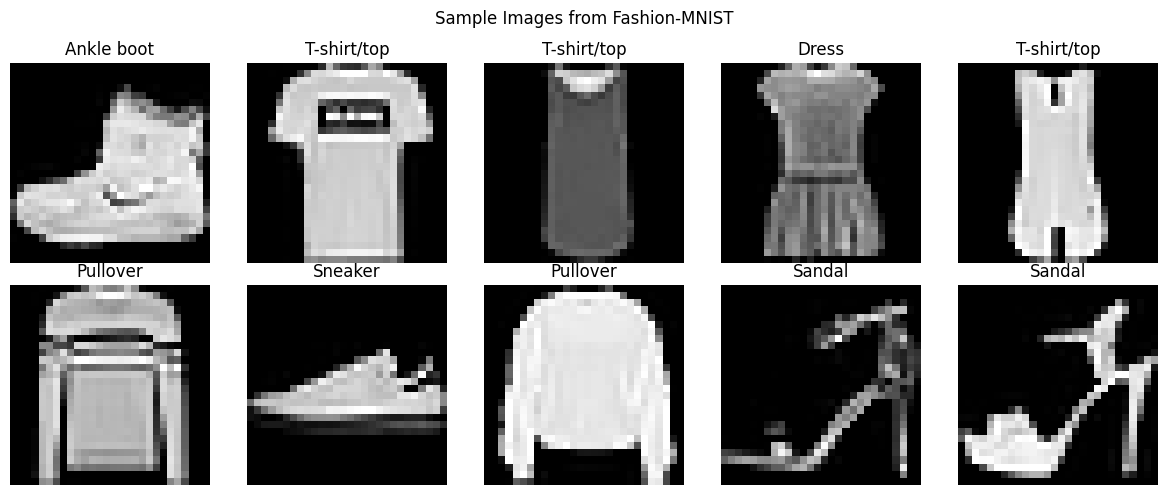

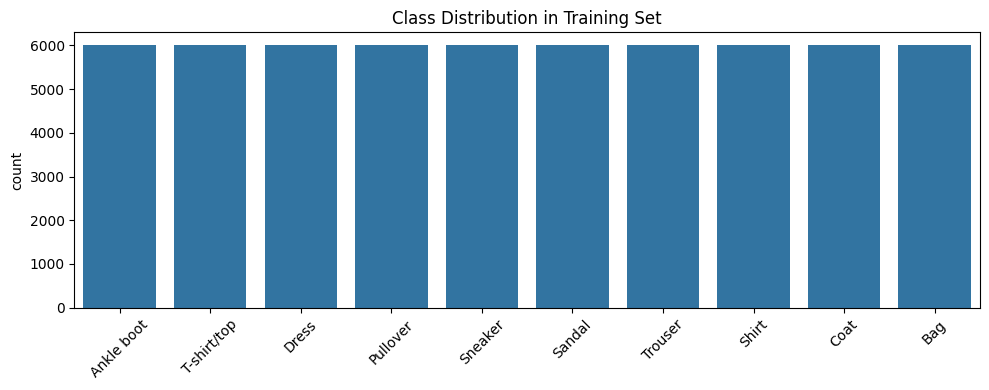

In [3]:
# Sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    img, label = full_train[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.suptitle("Sample Images from Fashion-MNIST")
plt.tight_layout()
plt.savefig("results/samples.png", dpi=150)
plt.show()

# Class distribution
labels = full_train.targets.numpy()
plt.figure(figsize=(10, 4))
sns.countplot(x=[CLASS_NAMES[l] for l in labels])
plt.xticks(rotation=45)
plt.title("Class Distribution in Training Set")
plt.tight_layout()
plt.savefig("results/class_distribution.png", dpi=150)
plt.show()


## 3. MLP Model

- **Flatten:** the 28×28 image becomes a 784-dimensional vector.
- **Linear → BatchNorm → ReLU → Dropout:** for each hidden layer.
  BatchNorm stabilizes training; Dropout reduces overfitting.
- **Output Linear:** 10 neurons, one per class.


In [4]:
class MLP(nn.Module):
    def __init__(self, hidden_sizes=(512, 256), dropout=0.2, num_classes=10):
        super().__init__()
        layers = [nn.Flatten()]
        in_features = 28 * 28
        for h in hidden_sizes:
            layers += [
                nn.Linear(in_features, h),
                nn.BatchNorm1d(h),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
            in_features = h
        layers.append(nn.Linear(in_features, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = MLP().to(device)
print(model)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 537354


## 4. Training and Evaluation Helpers

`run_epoch` runs one full pass over a data loader. If an optimizer is given,
the model trains and weights are updated; otherwise it only evaluates.


In [5]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * X.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += X.size(0)

    return total_loss / total, correct / total


## 5. Training with Early Stopping

- **Optimizer:** Adam, learning rate 1e-3, weight decay 1e-4
- **Scheduler:** ReduceLROnPlateau halves the learning rate when validation loss stops improving
- **Early stopping:** training stops after 5 epochs without improvement, and the best weights are restored


In [6]:
def train_model(model, epochs=30, lr=1e-3, weight_decay=1e-4, patience=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=2)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss, best_state, wait = float("inf"), None, 0

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        scheduler.step(va_loss)

        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
            history[k].append(v)

        print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
              f"| val loss {va_loss:.4f} acc {va_acc:.4f}")

        if va_loss < best_val_loss:
            best_val_loss, wait = va_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

model = MLP(hidden_sizes=(512, 256), dropout=0.2).to(device)
model, history = train_model(model, epochs=30, lr=1e-3)


Epoch 01 | train loss 0.4683 acc 0.8321 | val loss 0.3716 acc 0.8675
Epoch 02 | train loss 0.3581 acc 0.8682 | val loss 0.3516 acc 0.8705
Epoch 03 | train loss 0.3273 acc 0.8788 | val loss 0.3289 acc 0.8815
Epoch 04 | train loss 0.3031 acc 0.8868 | val loss 0.3130 acc 0.8855
Epoch 05 | train loss 0.2891 acc 0.8921 | val loss 0.3159 acc 0.8863
Epoch 06 | train loss 0.2774 acc 0.8957 | val loss 0.3063 acc 0.8913
Epoch 07 | train loss 0.2654 acc 0.9007 | val loss 0.3127 acc 0.8882
Epoch 08 | train loss 0.2572 acc 0.9029 | val loss 0.3155 acc 0.8865
Epoch 09 | train loss 0.2463 acc 0.9081 | val loss 0.3046 acc 0.8898
Epoch 10 | train loss 0.2421 acc 0.9094 | val loss 0.2837 acc 0.8978
Epoch 11 | train loss 0.2339 acc 0.9118 | val loss 0.2930 acc 0.8928
Epoch 12 | train loss 0.2281 acc 0.9139 | val loss 0.2962 acc 0.8918
Epoch 13 | train loss 0.2201 acc 0.9173 | val loss 0.2939 acc 0.8917
Epoch 14 | train loss 0.1846 acc 0.9311 | val loss 0.2721 acc 0.9018
Epoch 15 | train loss 0.1752 acc 0

## 6. Learning Curves

If the training and validation curves drift apart, the model is overfitting.


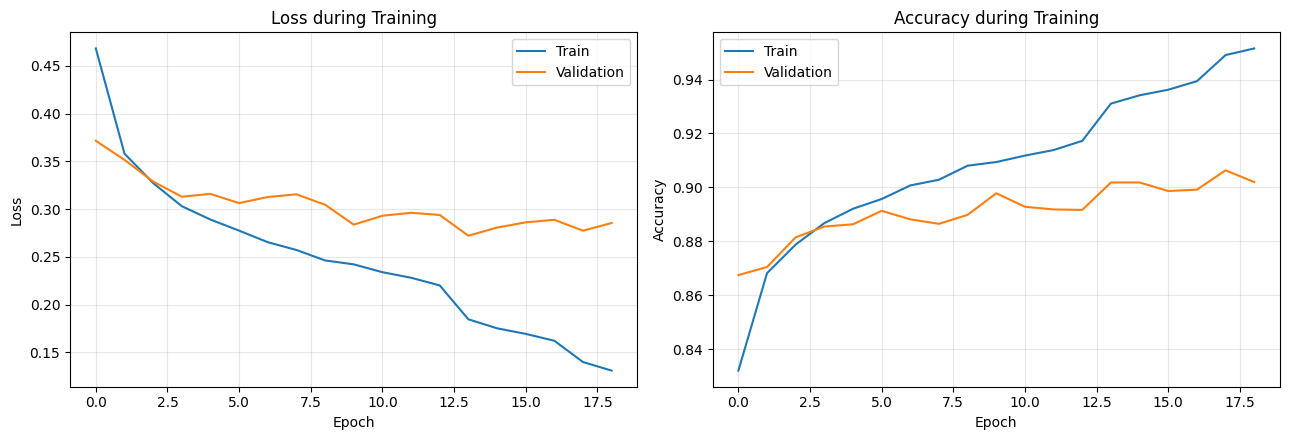

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["val_loss"], label="Validation")
ax1.set_title("Loss during Training")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(history["train_acc"], label="Train")
ax2.plot(history["val_acc"], label="Validation")
ax2.set_title("Accuracy during Training")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=150)
plt.show()


## 7. Test Set Evaluation

The test set is used only once, at the end. The classification report shows
precision, recall, and F1-score for each class.


In [8]:
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = run_epoch(model, test_loader, criterion)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for X, y in test_loader:
        preds = model(X.to(device)).argmax(1).cpu()
        all_preds.append(preds)
        all_labels.append(y)
all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))


Test Loss: 0.2859 | Test Accuracy: 0.9006
              precision    recall  f1-score   support

 T-shirt/top       0.83      0.89      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.80      0.85      0.83      1000
       Dress       0.92      0.90      0.91      1000
        Coat       0.83      0.84      0.84      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.77      0.68      0.72      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.96      0.96      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



## 8. Confusion Matrix

This shows which classes get confused with each other. We expect the most errors
between similar classes such as Shirt and T-shirt, or Pullover and Coat.


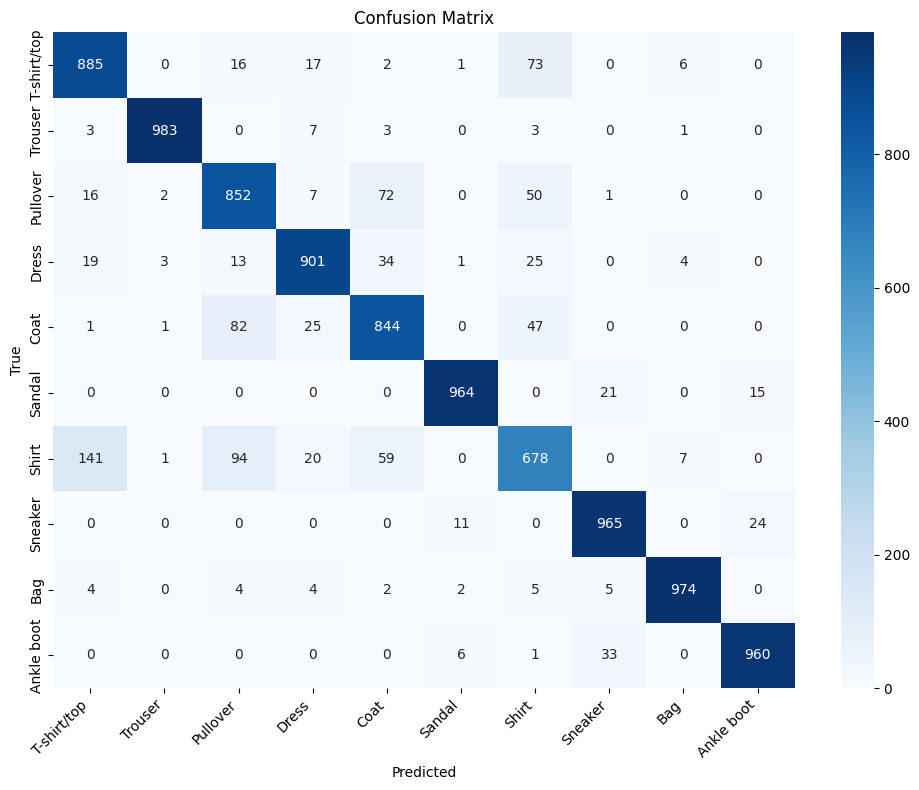

In [9]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150)
plt.show()


## 9. Misclassified Examples

We look at some wrong predictions to check whether the errors make sense.


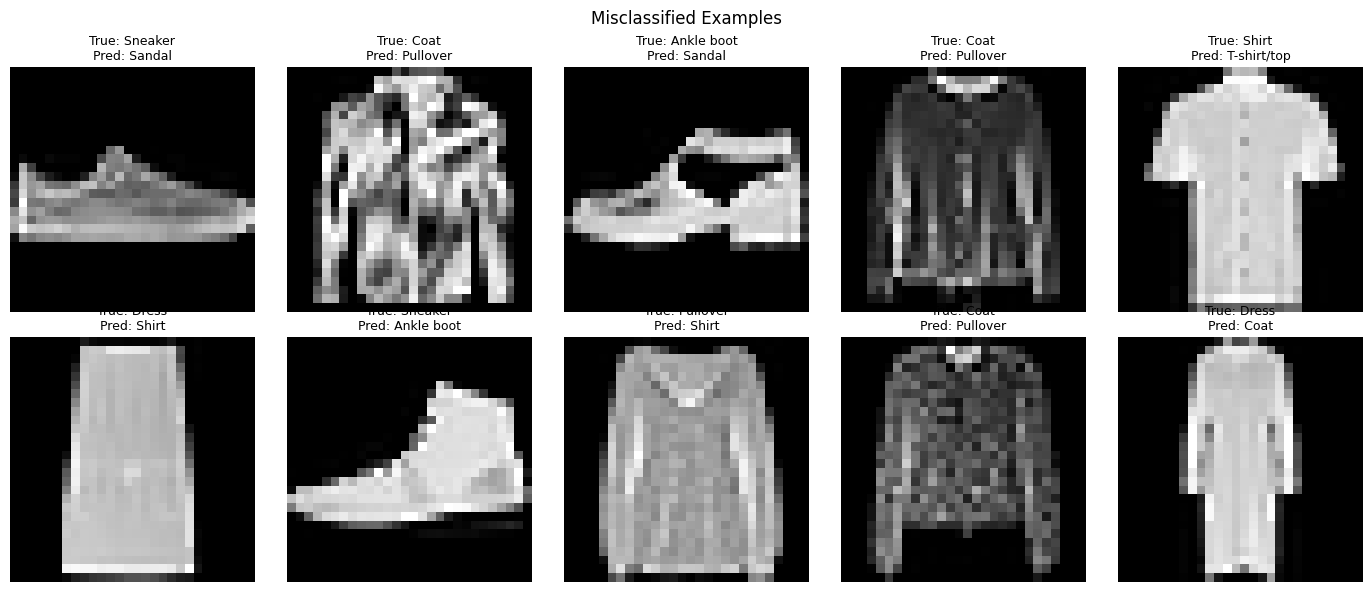

In [10]:
wrong_idx = np.where(all_preds != all_labels)[0][:10]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flat, wrong_idx):
    img, _ = test_set[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"True: {CLASS_NAMES[all_labels[i]]}\nPred: {CLASS_NAMES[all_preds[i]]}",
                 fontsize=9)
    ax.axis("off")
plt.suptitle("Misclassified Examples")
plt.tight_layout()
plt.savefig("results/misclassified.png", dpi=150)
plt.show()


## 10. Ablation Study

We compare architectures to justify design choices with data:
depth, width, and dropout rate. Each model uses the same seed and 30 epochs.


In [11]:
configs = [
    {"name": "Shallow (256)",        "hidden": (256,),           "dropout": 0.0},
    {"name": "Deep (512,256)",       "hidden": (512, 256),       "dropout": 0.0},
    {"name": "Deep + Dropout",       "hidden": (512, 256),       "dropout": 0.2},
    {"name": "Wider (1024,512,256)", "hidden": (1024, 512, 256), "dropout": 0.3},
]

results = []
for cfg in configs:
    print(f"\n=== {cfg['name']} ===")
    torch.manual_seed(SEED)
    m = MLP(hidden_sizes=cfg["hidden"], dropout=cfg["dropout"]).to(device)
    m, _ = train_model(m, epochs=30, lr=1e-3)
    _, acc = run_epoch(m, test_loader, nn.CrossEntropyLoss())
    results.append({"Model": cfg["name"], "Test Accuracy": round(acc, 4)})

df_results = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False)
print(df_results.to_string(index=False))
df_results.to_csv("results/ablation.csv", index=False)



=== Shallow (256) ===
Epoch 01 | train loss 0.4650 acc 0.8367 | val loss 0.3960 acc 0.8575
Epoch 02 | train loss 0.3476 acc 0.8749 | val loss 0.3588 acc 0.8738
Epoch 03 | train loss 0.3112 acc 0.8865 | val loss 0.3342 acc 0.8757
Epoch 04 | train loss 0.2840 acc 0.8969 | val loss 0.3221 acc 0.8822
Epoch 05 | train loss 0.2679 acc 0.9018 | val loss 0.3217 acc 0.8848
Epoch 06 | train loss 0.2500 acc 0.9097 | val loss 0.3096 acc 0.8842
Epoch 07 | train loss 0.2420 acc 0.9114 | val loss 0.3120 acc 0.8862
Epoch 08 | train loss 0.2293 acc 0.9166 | val loss 0.3139 acc 0.8878
Epoch 09 | train loss 0.2170 acc 0.9211 | val loss 0.3031 acc 0.8860
Epoch 10 | train loss 0.2063 acc 0.9244 | val loss 0.3049 acc 0.8878
Epoch 11 | train loss 0.1985 acc 0.9273 | val loss 0.3062 acc 0.8948
Epoch 12 | train loss 0.1916 acc 0.9307 | val loss 0.3095 acc 0.8897
Epoch 13 | train loss 0.1571 acc 0.9452 | val loss 0.2911 acc 0.8983
Epoch 14 | train loss 0.1478 acc 0.9494 | val loss 0.2984 acc 0.8947
Epoch 15 | 

## 11. Save and Reload the Model


In [12]:
torch.save(model.state_dict(), "models/mlp_fashion_mnist.pt")
print("Model saved.")

loaded = MLP().to(device)
loaded.load_state_dict(torch.load("models/mlp_fashion_mnist.pt", map_location=device))
_, acc = run_epoch(loaded, test_loader, nn.CrossEntropyLoss())
print(f"Accuracy after reloading: {acc:.4f}")


Model saved.
Accuracy after reloading: 0.9006


## 12. Conclusion

- **Best test accuracy:** 0.9016 (Deep + Dropout, hidden sizes 512-256, dropout 0.2)
- **Ablation results:** Deep + Dropout (0.9016) > Wider (0.9002) > Shallow (0.8977) > Deep without dropout (0.8967)
- **Key finding:** Adding Dropout to the deeper network improved test accuracy by about 0.5 percentage points. The training accuracy (about 0.95) is higher than the validation accuracy (about 0.90), which shows that the model still overfits somewhat.
- **Model persistence:** The reloaded model reached 0.9006 test accuracy, which confirms that saving and loading work correctly.
- **Next steps:** Try a CNN, which is better suited to image data, add data augmentation, or run a hyperparameter search with Optuna.
